# Matrix multiplication on Cortex-M4: naive vs CMSIS-DSP vs sparse (CSC)

This notebook analyzes the cycle counts collected by the benchmark. It runs **without the hardware**: it only needs the raw output file (`results.txt`) captured from the board.

**What is measured**

- Operation: `C = A · B`, with `A` dense and `B` sparse, both `N × N`.
- Kernels: a naive triple loop, a modified version of CMSIS-DSP matrix multiplication, and a custom sparse kernel that uses `B` in CSC format.
- Data types: `float32` and `q15`. Sizes: N = 3, 4, 7, 8, 15, 16. Optimization: `-O2`.
- Inputs are regenerated randomly on every iteration; the number of non-zeros (NZ) of `B` is fixed within a test case.
- The dense-to-CSC conversion happens **outside** the timed region, so the sparse numbers describe the *static sparsity* case (a constant sparse matrix, such as pruned weights).

**Column naming.** In the raw file, `n*` is the naive kernel, `d*` is the CMSIS kernel and `s*` is the sparse kernel. In the DataFrame below they become `n_*`, `c_*` (CMSIS) and `s_*`, each with `avg`, `max` and `min`.

**CMSIS customization** original `arm_mat_mult_q15` performs a transposition within its code, but such operation is not required either for naive (since it should be as simples as possible) as well as for sparse matrix, because _transposition_ is already embedded within CSC sparse structure. In order to make strategies comparable, a custom version of `arm_mat_mult_q15` was used: the matrix is transposed before calling `arm_mat_mult_q15`. That way, only multiplication is actually compared.

In [ ]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import urllib.request

# fetch results.txt directly from github
urllib.request.urlretrieve("https://github.com/thiagoton/cortex-m4-sparse-matrix-benchmark/blob/main/results.txt", "results.txt")

DATA_FILE = next((p for p in (Path("results.txt"), Path("data/results.txt")) if p.exists()), None)
assert DATA_FILE is not None, "results.txt not found (looked in ./ and ./data/)"

FIG_DIR = Path("figures")   # figures are saved here so the README can embed them
SAVE_FIGS = True
if SAVE_FIGS:
    FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
TYPES = ["f32", "q15"]
COLORS = {"naive": "tab:gray", "cmsis": "tab:blue", "sparse": "tab:red"}


def savefig(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Load and validate the data

In [2]:
LINE = re.compile(
    r"(?P<dtype>\w+), SZ: (?P<N>\d+), NZ: (?P<nz>\d+), "
    r"navg: (?P<n_avg>\d+), nmax: (?P<n_max>\d+), nmin: (?P<n_min>\d+), "
    r"davg: (?P<c_avg>\d+), dmax: (?P<c_max>\d+), dmin: (?P<c_min>\d+), "
    r"savg: (?P<s_avg>\d+), smax: (?P<s_max>\d+), smin: (?P<s_min>\d+)"
)

rows = []
for line in DATA_FILE.read_text().splitlines():
    m = LINE.match(line.strip())
    if m:
        d = m.groupdict()
        rows.append({"dtype": d.pop("dtype"), **{k: int(v) for k, v in d.items()}})

df = pd.DataFrame(rows).sort_values(["dtype", "N", "nz"]).reset_index(drop=True)
SIZES = sorted(df.N.unique())
print(f"{len(df)} test cases from {DATA_FILE}")
df.groupby(["dtype", "N"]).agg(cases=("nz", "size"), nz_min=("nz", "min"), nz_max=("nz", "max"))

112 test cases from results.txt


cases  nz_min  nz_max
dtype N                        
f32   3       5       1       9
      4       8       1      15
      7      13       1      49
      8       8       1      64
      15     11       1     221
      16     11       1     251
q15   3       5       1       9
      4       8       1      15
      7      13       1      49
      8       8       1      64
      15     11       1     221
      16     11       1     251

In [3]:
# Derived metrics
df["density"] = df.nz / df.N**2
df["macs_dense"] = df.N**3          # MACs of a dense N x N times N x N product
df["macs_sparse"] = df.N * df.nz    # useful MACs: each non-zero touches N rows of A

df["n_cpm"] = df.n_avg / df.macs_dense   # cycles per MAC, naive
df["c_cpm"] = df.c_avg / df.macs_dense   # cycles per MAC, CMSIS
df["s_cpm"] = df.s_avg / df.macs_sparse  # cycles per useful MAC, sparse

df["speedup_cmsis"] = df.c_avg / df.s_avg   # > 1 means sparse is faster
df["speedup_naive"] = df.n_avg / df.s_avg
df["s_max_over_avg"] = df.s_max / df.s_avg
df["s_spread"] = (df.s_max - df.s_min) / df.s_avg

# The dense kernels do not depend on NZ: keep one row per (dtype, N) for them
dense = (df.groupby(["dtype", "N"])[["n_avg", "c_avg", "n_cpm", "c_cpm"]]
           .mean().reset_index())

df.to_csv("results.csv", index=False)   # tidy copy, convenient to commit next to the notebook


def sub(dtype, N):
    return df[(df.dtype == dtype) & (df.N == N)].sort_values("nz")


# Sanity check: the dense kernels should be flat across sparsity
print("max over cases of (dense avg - dense avg of the same dtype/N):")
print("  naive:", int((df.n_avg - df.groupby(["dtype", "N"]).n_avg.transform("mean")).abs().max()))
print("  CMSIS:", int((df.c_avg - df.groupby(["dtype", "N"]).c_avg.transform("mean")).abs().max()))
print("dense kernels, max(max - min) over all cases:  naive =",
      int((df.n_max - df.n_min).max()), "| CMSIS =", int((df.c_max - df.c_min).max()))

max over cases of (dense avg - dense avg of the same dtype/N):
  naive: 0
  CMSIS: 0
dense kernels, max(max - min) over all cases:  naive = 0 | CMSIS = 0


## 2. Cycles vs number of non-zeros

The red band is the min-max range of the sparse kernel and the red line its average. The dashed lines are the dense kernels, which do the same work whatever the sparsity.

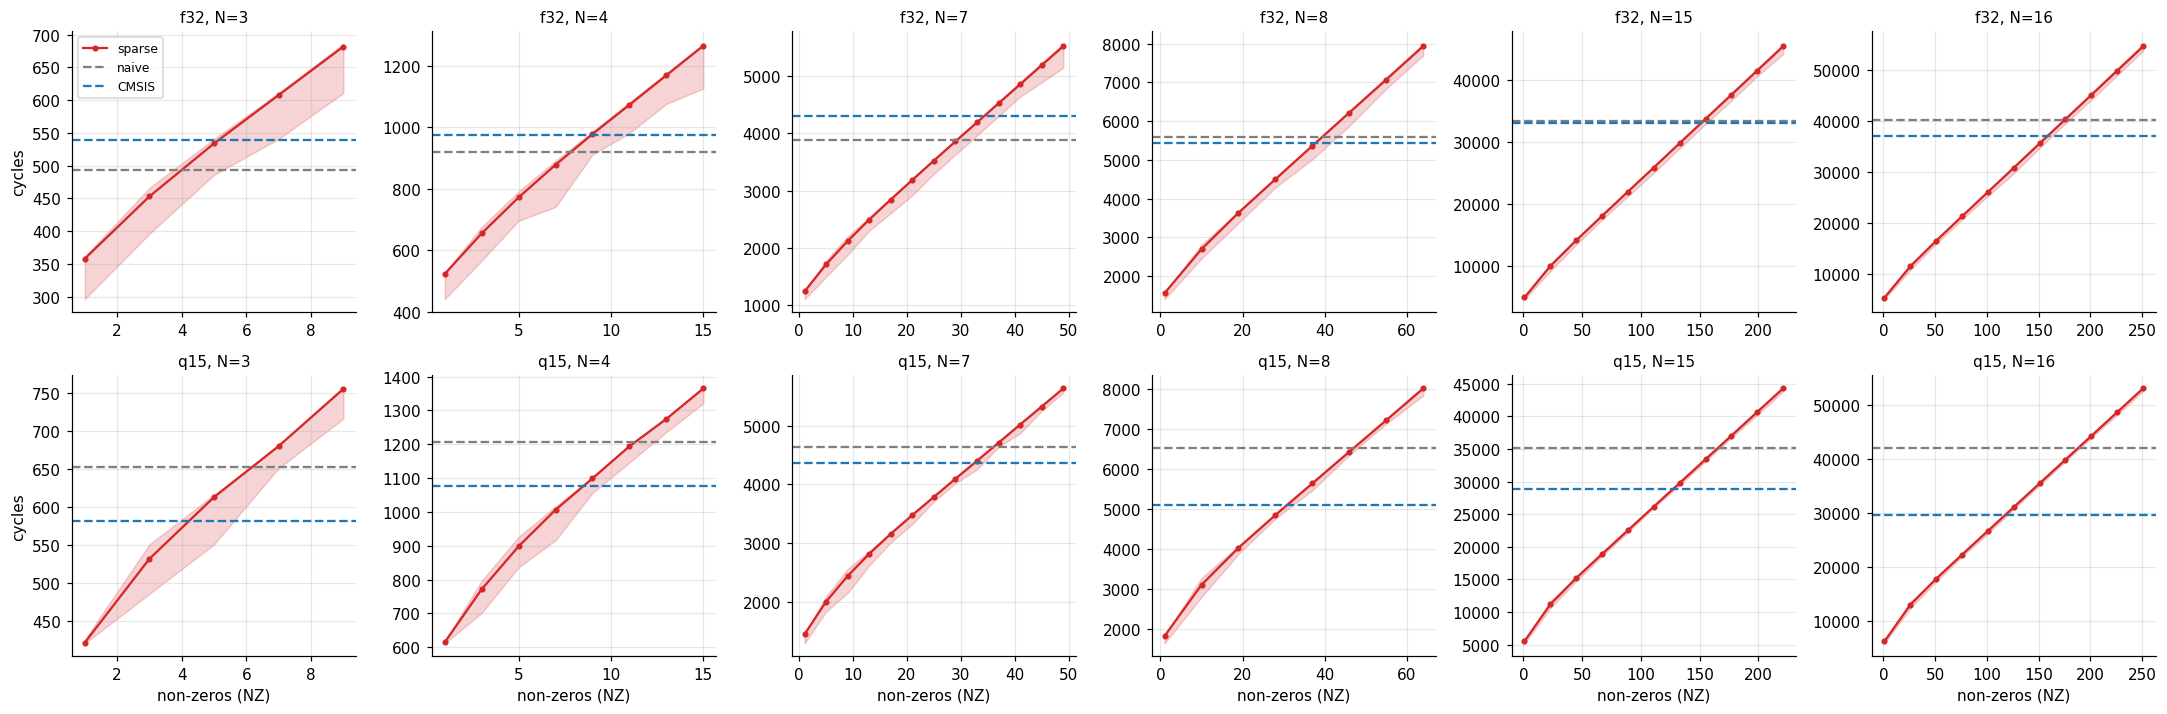

In [4]:
fig, axes = plt.subplots(len(TYPES), len(SIZES), figsize=(3.3 * len(SIZES), 6.6), squeeze=False)
for i, t in enumerate(TYPES):
    for j, N in enumerate(SIZES):
        ax, d = axes[i, j], sub(t, N)
        ax.fill_between(d.nz, d.s_min, d.s_max, color=COLORS["sparse"], alpha=0.2)
        ax.plot(d.nz, d.s_avg, "o-", ms=3, color=COLORS["sparse"], label="sparse")
        ax.axhline(d.n_avg.mean(), color=COLORS["naive"], ls="--", label="naive")
        ax.axhline(d.c_avg.mean(), color=COLORS["cmsis"], ls="--", label="CMSIS")
        ax.set_title(f"{t}, N={N}", fontsize=10)
        if i == len(TYPES) - 1:
            ax.set_xlabel("non-zeros (NZ)")
        if j == 0:
            ax.set_ylabel("cycles")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "cycles_vs_nz")
plt.show()

## 3. Break-even density: where does sparse stop winning?

The sparse cycles are almost linear in NZ, so the break-even is found by fitting `cycles = a + b·NZ` and intersecting the line with the (constant) dense cost. The column `observed_bracket_cmsis` shows the two measured NZ values that enclose the crossing, as a check that the fit agrees with the raw data. Because NZ is sampled on a coarse grid, treat the break-evens as accurate to about ±5 points of density. For lower size kernels, `a/N**2` changes significantly (3 &rarr; 4 vs 15 &rarr; 16). As `N` increases, `a/N**2` seems to converge.

In [5]:
def fit_line(d):
    b, a = np.polyfit(d.nz, d.s_avg, 1)
    pred = a + b * d.nz
    r2 = 1 - ((d.s_avg - pred) ** 2).sum() / ((d.s_avg - d.s_avg.mean()) ** 2).sum()
    return a, b, r2


def crossing(d, ref):
    a, b, _ = fit_line(d)
    return (ref - a) / b


def bracket(d, ref):
    below, above = d[d.s_avg < ref], d[d.s_avg >= ref]
    lo = int(below.nz.max()) if len(below) else None
    hi = int(above.nz.min()) if len(above) else None
    return f"{lo}-{hi}"


recs = []
for t in TYPES:
    for N in SIZES:
        d = sub(t, N)
        a, b, r2 = fit_line(d)
        c_ref, n_ref = d.c_avg.mean(), d.n_avg.mean()
        nz_c, nz_n = crossing(d, c_ref), crossing(d, n_ref)
        recs.append(dict(
            dtype=t, N=N, a=a, b=b, r2=r2, a_per_N2=a / N**2, b_per_N=b / N,
            breakeven_cmsis_nz=nz_c, breakeven_cmsis_density=nz_c / N**2,
            breakeven_naive_nz=nz_n, breakeven_naive_density=nz_n / N**2,
            observed_bracket_cmsis=bracket(d, c_ref),
        ))
fits = pd.DataFrame(recs)

(fits[["dtype", "N", "breakeven_cmsis_nz", "breakeven_cmsis_density",
       "observed_bracket_cmsis", "breakeven_naive_density", "a_per_N2", "b_per_N", "r2"]]
 .round(3))

,dtype,N,breakeven_cmsis_nz,breakeven_cmsis_density,observed_bracket_cmsis,breakeven_naive_density,a_per_N2,b_per_N,r2
0,f32,3,5.324,0.592,5-7,0.461,36.250,13.383,0.997
1,f32,4,9.167,0.573,7-9,0.508,31.041,13.046,0.997
2,f32,7,34.485,0.704,33-37,0.603,26.596,12.435,0.998
3,f32,8,38.188,0.597,37-46,0.622,25.622,12.423,0.998
4,f32,15,151.815,0.675,133-155,0.681,24.670,12.118,0.999
5,f32,16,158.650,0.620,151-176,0.685,24.647,12.095,0.999
6,q15,3,4.523,0.503,3-5,0.696,44.100,13.567,0.990
7,q15,4,8.926,0.558,7-9,0.716,38.169,13.033,0.988
8,q15,7,32.813,0.670,29-33,0.736,33.242,11.938,0.994
9,q15,8,32.195,0.503,28-37,0.737,31.799,11.923,0.994


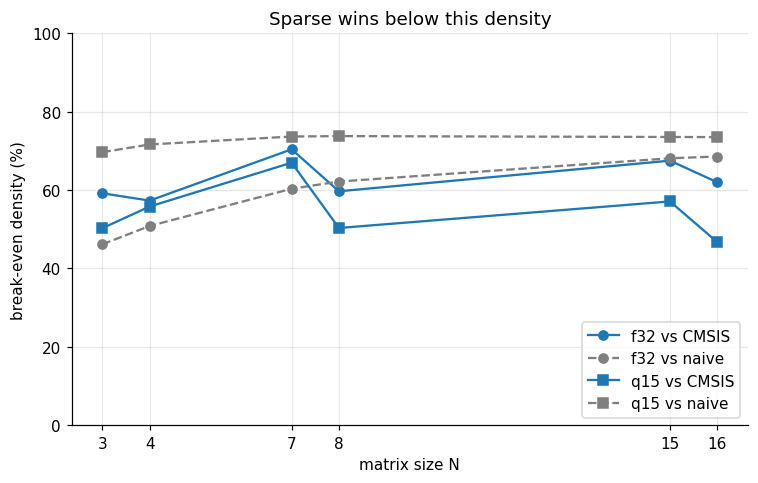

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for t, mk in zip(TYPES, ("o", "s")):
    f = fits[fits.dtype == t]
    ax.plot(f.N, f.breakeven_cmsis_density * 100, mk + "-", color=COLORS["cmsis"], label=f"{t} vs CMSIS")
    ax.plot(f.N, f.breakeven_naive_density * 100, mk + "--", color=COLORS["naive"], label=f"{t} vs naive")
ax.set_xticks(SIZES)
ax.set_ylim(0, 100)
ax.set_xlabel("matrix size N")
ax.set_ylabel("break-even density (%)")
ax.set_title("Sparse wins below this density")
ax.legend(loc='lower right')
fig.tight_layout()
savefig(fig, "breakeven_density")
plt.show()

## 4. Speedup of the sparse kernel vs density

Values above 1 mean the sparse kernel is faster than CMSIS. The speedup at low density grows with N, because the dense kernels scale with N³ while the sparse one scales roughly with N². As density increases, sparse loses advantage and roughly at 50-60% density CMSIS outperforms sparse multiplication.

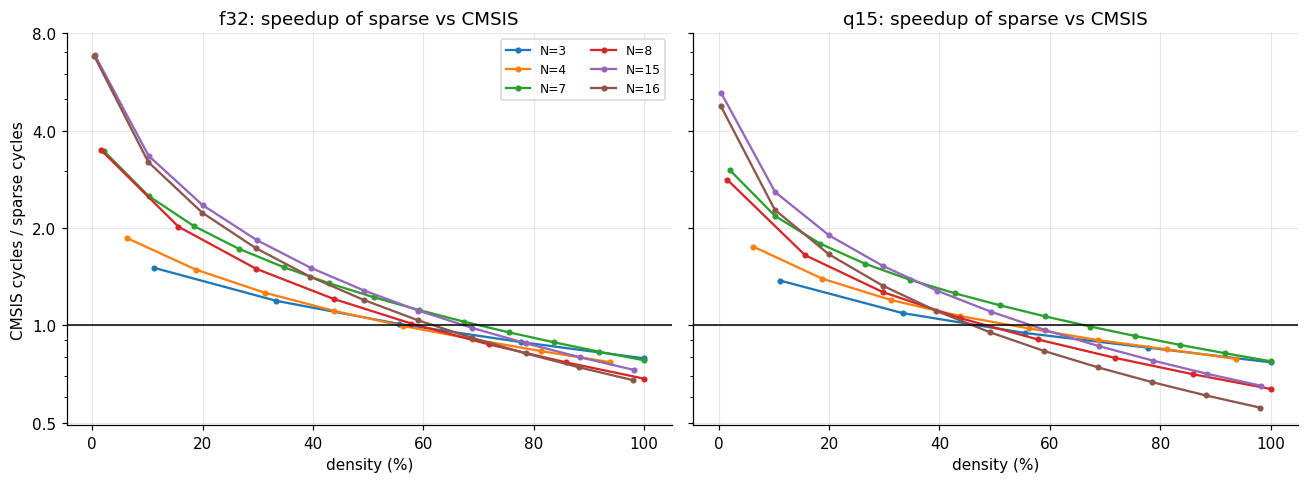

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, t in zip(axes, TYPES):
    for N in SIZES:
        d = sub(t, N)
        ax.plot(d.density * 100, d.speedup_cmsis, "o-", ms=3, label=f"N={N}")
    ax.axhline(1, color="k", lw=1)
    ax.set_yscale("log")
    ax.set_yticks([0.5, 1, 2, 4, 8])
    ax.yaxis.set_major_formatter(mt.ScalarFormatter())
    ax.yaxis.set_minor_formatter(mt.NullFormatter())
    ax.set_title(f"{t}: speedup of sparse vs CMSIS")
    ax.set_xlabel("density (%)")
axes[0].set_ylabel("CMSIS cycles / sparse cycles")
axes[0].legend(ncol=2, fontsize=8)
fig.tight_layout()
savefig(fig, "speedup_vs_density")
plt.show()

In [8]:
# Best case (lowest NZ) and worst case (highest NZ) of the sparse kernel, vs CMSIS and naive
lo = df.loc[df.groupby(["dtype", "N"]).nz.idxmin()].set_index(["dtype", "N"])
hi = df.loc[df.groupby(["dtype", "N"]).nz.idxmax()].set_index(["dtype", "N"])
extremes = pd.DataFrame({
    "nz_lowest": lo.nz,
    "speedup_vs_cmsis_lowest_nz": lo.speedup_cmsis,
    "speedup_vs_naive_lowest_nz": lo.speedup_naive,
    "nz_highest": hi.nz,
    "density_highest": hi.density,
    "sparse_vs_cmsis_highest_nz": hi.s_avg / hi.c_avg,   # > 1: sparse is slower
})
extremes.round(2)

nz_lowest  speedup_vs_cmsis_lowest_nz  speedup_vs_naive_lowest_nz  nz_highest  density_highest  sparse_vs_cmsis_highest_nz
dtype N                                                                                                                             
f32   3           1                        1.51                        1.38           9             1.00                        1.26
      4           1                        1.86                        1.76          15             0.94                        1.30
      7           1                        3.47                        3.12          49             1.00                        1.28
      8           1                        3.49                        3.59          64             1.00                        1.46
      15          1                        6.86                        6.91         221             0.98                        1.37
      16          1                        6.78                        7.38         251             0.98                        1.48
q15   3           1                        1.38                        1.55           9             1.00                        1.30
      4           1                        1.75                        1.97          15             0.94                        1.27
      7           1                        3.02                        3.20          49             1.00                        1.29
      8           1                        2.82                        3.61          64             1.00                        1.57
      15          1                        5.23                        6.37         221             0.98                        1.53
      16          1                        4.76                        6.77         251             0.98                        1.79

## 6. Cycles per MAC

Cycles per MAC normalizes cost across sizes and kernels: `cycles / N³` for the dense kernels and `cycles / (N · NZ)` for the sparse one. Note that for all matrix sizes, sparse pays a higher price (cycles per MAC) for lower density (greater than 100 cycles/MAC vs ~20 cycles/MAC for dense), but since there are fewer MACs to perform, the final cost is still lower than dense methods.

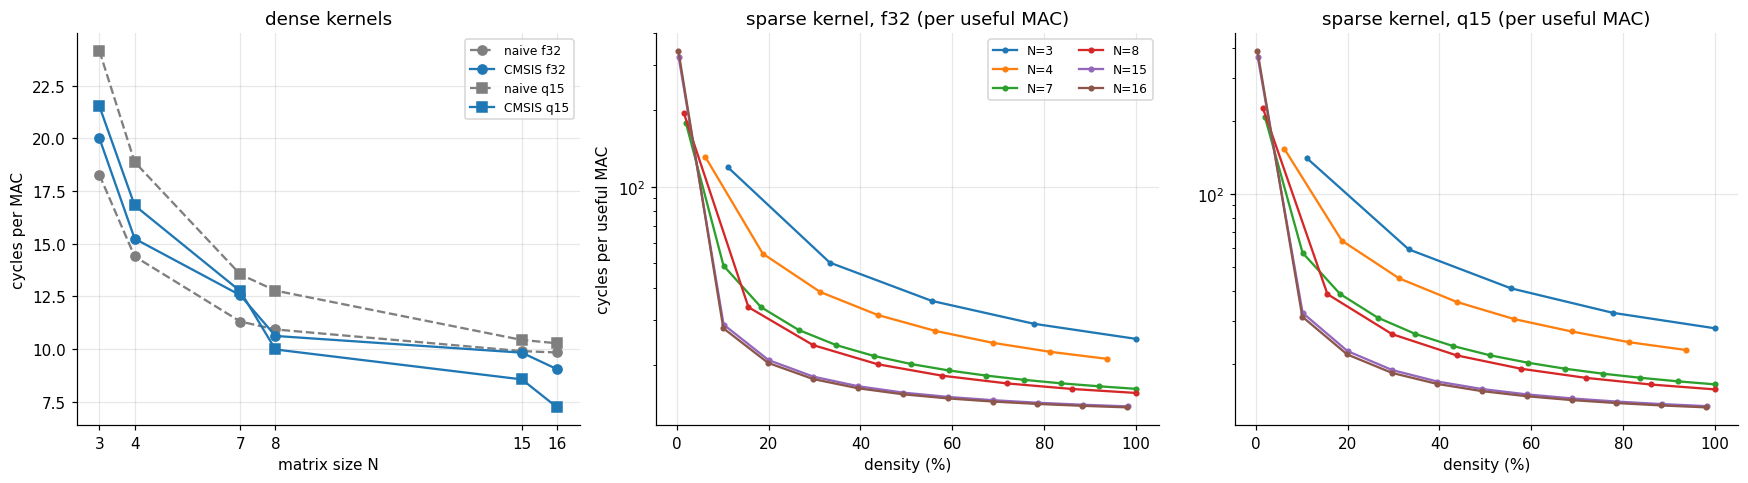

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for t, mk in zip(TYPES, ("o", "s")):
    r = dense[dense.dtype == t]
    axes[0].plot(r.N, r.n_cpm, mk + "--", color=COLORS["naive"], label=f"naive {t}")
    axes[0].plot(r.N, r.c_cpm, mk + "-", color=COLORS["cmsis"], label=f"CMSIS {t}")
axes[0].set_xticks(SIZES)
axes[0].set_xlabel("matrix size N")
axes[0].set_ylabel("cycles per MAC")
axes[0].set_title("dense kernels")
axes[0].legend(fontsize=8)

for ax, t in zip(axes[1:], TYPES):
    for N in SIZES:
        d = sub(t, N)
        ax.plot(d.density * 100, d.s_cpm, "o-", ms=3, label=f"N={N}")
    ax.set_yscale("log")
    ax.set_xlabel("density (%)")
    ax.set_title(f"sparse kernel, {t} (per useful MAC)")
axes[1].set_ylabel("cycles per useful MAC")
axes[1].legend(ncol=2, fontsize=8)
fig.tight_layout()
savefig(fig, "cycles_per_mac")
plt.show()

## 7. Naive vs CMSIS

A ratio below 1 means CMSIS is faster than the naive loop compiled with `-O2`. Interestingly, naive outperforms CMSIS for kernels [3,4,7]. CMSIS implementation `arm_mat_mult_f32` performs loop unrolling, doing 4 MACs within a single loop, in order to reduce management overhead during operation. But that has an additional cost: by unrolling the loop, it is also needed to handle the remainder MACs not performed within unrolled loop. For small kernels, tha performance improvement made by loop unrolling it is not visible. The penalty imposed by unrolling loop is only amortized for `N=8`.

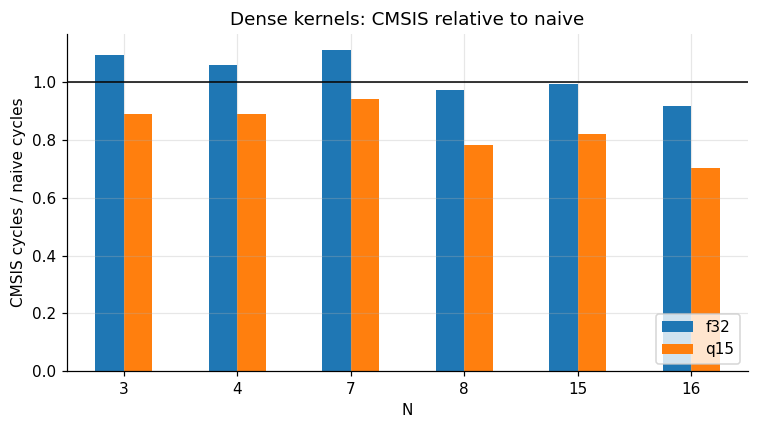

dtype,f32,q15
N,,
3,1.095,0.891
4,1.059,0.891
7,1.111,0.941
8,0.972,0.781
15,0.993,0.820
16,0.919,0.704


In [10]:
dense["cmsis_over_naive"] = dense.c_avg / dense.n_avg
piv = dense.pivot(index="N", columns="dtype", values="cmsis_over_naive")
ax = piv.plot.bar(figsize=(7, 4), rot=0)
ax.legend(loc='lower right')
ax.axhline(1, color="k", lw=1)
ax.set_ylabel("CMSIS cycles / naive cycles")
ax.set_title("Dense kernels: CMSIS relative to naive")
ax.figure.tight_layout()
savefig(ax.figure, "cmsis_vs_naive")
plt.show()
piv.round(3)

## 8. Odd sizes vs powers of two

CMSIS processes data in pairs and has to handle a tail for odd dimensions, so odd sizes may pay a penalty. The naive loop is used as a **control**: if both kernels improve by the same amount going from N=7 to 8, that is just the general size trend; if only CMSIS improves, parity matters. As can be verified, optimization made in CMSIS, like loop unrolling and SIMD instructions, made a significant impact when `N` is a power of 2 (7 &rarr; 8 and 15 &rarr; 16)

In [11]:
pairs = [(3, 4), (7, 8), (15, 16)]
recs = []
for t in TYPES:
    r = dense[dense.dtype == t].set_index("N")
    for odd, even in pairs:
        if odd in r.index and even in r.index:
            recs.append(dict(
                dtype=t, step=f"{odd} -> {even}",
                cmsis_cpm_change_pct=(r.c_cpm[even] / r.c_cpm[odd] - 1) * 100,
                naive_cpm_change_pct=(r.n_cpm[even] / r.n_cpm[odd] - 1) * 100,
            ))
parity = pd.DataFrame(recs)
parity.round(1)

,dtype,step,cmsis_cpm_change_pct,naive_cpm_change_pct
0,f32,3 -> 4,-23.8,-21.2
1,f32,7 -> 8,-15.4,-3.3
2,f32,15 -> 16,-8.0,-0.7
3,q15,3 -> 4,-21.9,-21.8
4,q15,7 -> 8,-21.7,-5.7
5,q15,15 -> 16,-15.5,-1.5


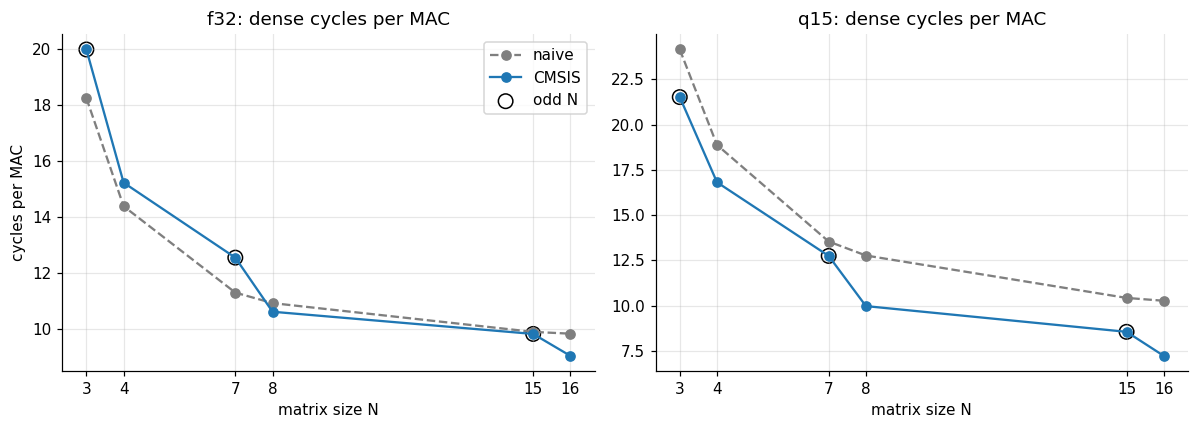

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, t in zip(axes, TYPES):
    r = dense[dense.dtype == t]
    ax.plot(r.N, r.n_cpm, "o--", color=COLORS["naive"], label="naive")
    ax.plot(r.N, r.c_cpm, "o-", color=COLORS["cmsis"], label="CMSIS")
    odd = r[r.N % 2 == 1]
    ax.scatter(odd.N, odd.c_cpm, s=90, facecolors="none", edgecolors="k", label="odd N")
    ax.set_xticks(SIZES)
    ax.set_xlabel("matrix size N")
    ax.set_title(f"{t}: dense cycles per MAC")
axes[0].set_ylabel("cycles per MAC")
axes[0].legend()
fig.tight_layout()
savefig(fig, "odd_vs_even")
plt.show()

## 9. Variability and worst case

The dense kernels are deterministic (min = max). For the sparse kernel the spread comes from where the random non-zeros happen to fall. The max/avg ratio is what matters for a worst-case argument. Random placement does **not** cover adversarial layouts (for example all non-zeros in one column), so this is not a proper WCET bound.

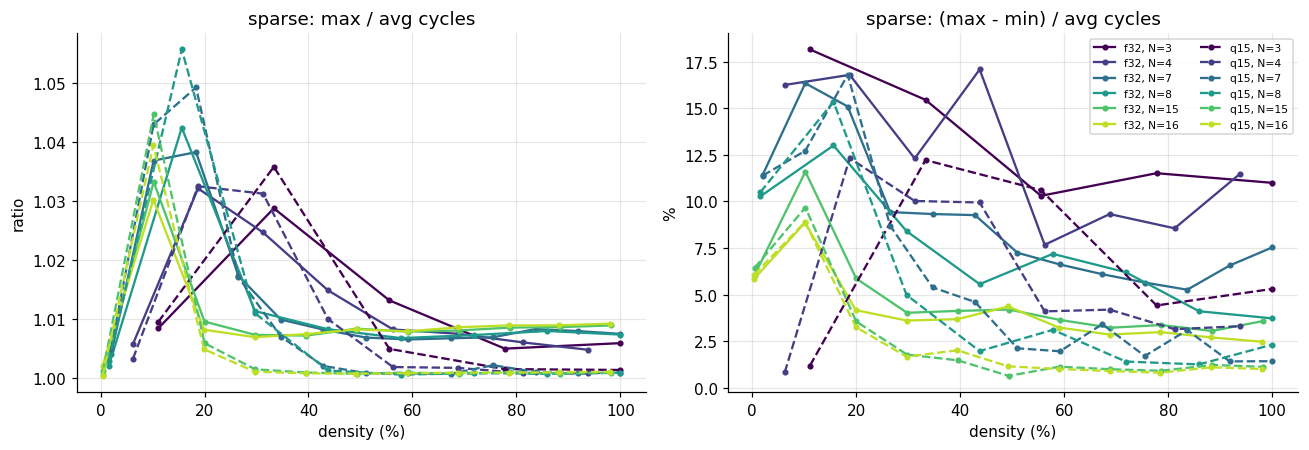

In [13]:
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(SIZES)))
styles = {"f32": "-", "q15": "--"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for t in TYPES:
    for color, N in zip(cmap, SIZES):
        d = sub(t, N)
        axes[0].plot(d.density * 100, d.s_max_over_avg, styles[t], color=color, marker="o", ms=3)
        axes[1].plot(d.density * 100, d.s_spread * 100, styles[t], color=color, marker="o", ms=3,
                     label=f"{t}, N={N}")
axes[0].set_title("sparse: max / avg cycles")
axes[0].set_ylabel("ratio")
axes[1].set_title("sparse: (max - min) / avg cycles")
axes[1].set_ylabel("%")
for ax in axes:
    ax.set_xlabel("density (%)")
axes[1].legend(ncol=2, fontsize=7)
fig.tight_layout()
savefig(fig, "variability")
plt.show()

In [14]:
(df.groupby(["dtype", "N"])
   .agg(max_over_avg_worst=("s_max_over_avg", "max"),
        spread_worst_pct=("s_spread", lambda s: 100 * s.max()))
   .round(3))

max_over_avg_worst  spread_worst_pct
dtype N                                       
f32   3                1.029            18.156
      4                1.032            17.084
      7                1.038            16.346
      8                1.042            13.001
      15               1.033            11.596
      16               1.030             8.858
q15   3                1.036            12.218
      4                1.032            12.322
      7                1.049            16.796
      8                1.056            15.352
      15               1.045             9.670
      16               1.039             8.895

## 10. Summary table

In [15]:
summary = pd.DataFrame({
    "naive_cycles": dense.set_index(["dtype", "N"]).n_avg,
    "cmsis_cycles": dense.set_index(["dtype", "N"]).c_avg,
}).join(fits.set_index(["dtype", "N"])[["breakeven_cmsis_density", "breakeven_naive_density"]]) \
  .join(extremes[["speedup_vs_cmsis_lowest_nz", "sparse_vs_cmsis_highest_nz"]])
summary["breakeven_cmsis_density"] = (summary.breakeven_cmsis_density * 100).round(0)
summary["breakeven_naive_density"] = (summary.breakeven_naive_density * 100).round(0)
summary.to_csv("summary.csv")
summary.round(2)

naive_cycles  cmsis_cycles  breakeven_cmsis_density  breakeven_naive_density  speedup_vs_cmsis_lowest_nz  sparse_vs_cmsis_highest_nz
dtype N                                                                                                                                       
f32   3          493.0         540.0                     59.0                     46.0                        1.51                        1.26
      4          921.0         975.0                     57.0                     51.0                        1.86                        1.30
      7         3876.0        4305.0                     70.0                     60.0                        3.47                        1.28
      8         5593.0        5435.0                     60.0                     62.0                        3.49                        1.46
      15       33394.0       33145.0                     67.0                     68.0                        6.86                        1.37
      16       40264.0       37011.0                     62.0                     69.0                        6.78                        1.48
q15   3          652.0         581.0                     50.0                     70.0                        1.38                        1.30
      4         1208.0        1076.0                     56.0                     72.0                        1.75                        1.27
      7         4644.0        4371.0                     67.0                     74.0                        3.02                        1.29
      8         6537.0        5106.0                     50.0                     74.0                        2.82                        1.57
      15       35184.0       28861.0                     57.0                     74.0                        5.23                        1.53
      16       42055.0       29586.0                     47.0                     73.0                        4.76                        1.79

## Limitations

- **Coarse NZ grid.** Break-evens are accurate to about ±5 points of density.
- **Sweep does not reach 100% density** for some sizes (the largest NZ is below N² for N = 4, 15 and 16).
- **Static sparsity only.** The CSC conversion is not timed. Add the conversion cost separately if the matrix changes at runtime.
- **Small matrices only.** Sizes up to 16 describe the small-matrix regime typical of control and small NN layers; the trends may change for larger N.
- **Random placement.** Non-zeros are placed at random, so structured patterns (banded, block, diagonal) are not covered.